# Python data basics for Hist2ST

This notebook prepares you for [Onboarding 01 - Data preparation](../notebooks/onbd_01_data_preparation.ipynb). It assumes introductory Python: variables, lists and dictionaries, loops, functions, and a first look at classes/objects. It assumes **no prior experience** with scientific Python libraries.

You will meet the tools used in Onboarding 01 through small examples: Jupyter, Pandas, NumPy, `pathlib`, HDF5/`h5py`, AnnData, SciPy sparse matrices, Matplotlib, and Hugging Face Hub. You do not need to memorize the APIs; use this notebook to recognize what each object represents and follow the later data workflow.

Examples use toy data and temporary files. Hugging Face download is optional and disabled by default.


## 1. Jupyter notebooks: cells and outputs

A notebook is a document made of cells. Markdown cells explain the work; code cells run Python. Run a code cell with Shift+Enter and read the output directly below it.

The **kernel** is the running Python process that executes your code. It remembers variables, functions, and imported libraries between cells. The notebook is the document you see; the kernel does the computation. Restarting the kernel clears that memory, so run the cells again from the top to recreate it. Saved code and output remain in the notebook file.

### Python scripts and notebooks

A normal Python script (`.py`) is a text file of Python code. When you run `python example.py`, Python normally starts a new process, executes the file from top to bottom, and exits. Printed output appears in the terminal; variable values from that run are not automatically kept for the next run.

A notebook (`.ipynb`) combines code cells, explanatory text, and saved output such as tables or plots. You can run one cell at a time, rerun it, or run cells in a different order. Its kernel keeps variables between cells until it is restarted or shut down. This is useful for exploring data, but it also means a result can depend on cells you ran earlier. To check that the notebook works as written, restart the kernel and run all cells from top to bottom.

Both execute Python. In this project, notebooks explain and display each experiment, while reusable functions in `src/` live in ordinary `.py` files that notebooks can import.


In [47]:
message = 'This is the output from a code cell.'
print(message)


This is the output from a code cell.


## 2. Install and import libraries

A library provides reusable code beyond Python's built-in functions. Installing a package saves its files in a Python environment. The notebook's selected kernel uses a particular environment; `%pip` installs into that kernel's environment so its Python process can find the package. `-q` (quiet mode) stops printing messages during installation. A package installed in a different environment may be unavailable to this kernel.

Installation and importing are separate steps: installation puts the files on disk, while `import` makes the library available to your running code. Restarting the kernel does not uninstall packages. After a restart, rerun the import and example cells; the installed files remain available in the same environment. Temporary Colab runtimes can lose installations when the runtime itself is replaced. Occasionally an upgraded package that was already imported requires a restart to load its new version.

In [48]:
# Standard-library imports
from pathlib import Path
import tempfile

In [49]:
# Package imports: Install first
%pip install -q numpy

Note: you may need to restart the kernel to use updated packages.


In [50]:
import numpy as np

# NumPy's linspace returns five evenly spaced numbers from 0 to 1, including both endpoints.
values = np.linspace(0, 1, num=5)
print(values)  # [0.   0.25 0.5  0.75 1.  ]

[0.   0.25 0.5  0.75 1.  ]


Install each library once in the notebook environment, near the top. Repeating installation commands in later sections is unnecessary: the package files stay installed in that environment, and pip downloads them only when they are missing or need a different version. An import makes an installed library available to the current Python process; after restarting the kernel, rerun imports, but do not reinstall packages unless the environment was replaced or the package is missing. In real notebooks, we will keep all installation commands and imports together at the top so setup is easy to find and the examples below focus on using the libraries.

In [51]:
%pip install -q pandas h5py anndata scipy matplotlib huggingface_hub

Note: you may need to restart the kernel to use updated packages.


In [52]:
# Other third-party imports used throughout this notebook
import pandas as pd
import h5py
import anndata
import scipy.sparse as sparse
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download, login, whoami

## 3. `pathlib`: describing files and folders
A `Path` object represents a file or folder location. The `/` operator joins path pieces; methods such as `.exists()` and `.mkdir()` inspect or create folders. The cell writes only inside a temporary folder, which Python removes when the context ends. In Onboarding 01, `DATA_DIR` is a `Path` constant that you edit to choose shared Drive or local storage.

In [53]:
with tempfile.TemporaryDirectory() as temporary_folder:
    demo_dir = Path(temporary_folder) / 'demo_data'
    demo_dir.mkdir(parents=True, exist_ok=True)
    demo_file = demo_dir / 'notes.txt'
    demo_file.write_text('A file inside a temporary folder.', encoding='utf-8')
    print('Folder exists:', demo_dir.exists())
    print('File contents:', demo_file.read_text(encoding='utf-8'))


Folder exists: True
File contents: A file inside a temporary folder.


## 4. Pandas: working with tables
Pandas stores labeled rows and columns in a `DataFrame`, much like a spreadsheet or database table. Column names help you identify what a value means. Here each row describes one tissue spot.

In [54]:
spots = pd.DataFrame({
    'sample_id': ['S1', 'S1', 'S2', 'S2'],
    'patient': ['P1', 'P1', 'P2', 'P2'],
    'barcode': ['bc-a', 'bc-b', 'bc-c', 'bc-d'],
    'x': [10, 20, 12, 22],
    'y': [5, 5, 15, 15],
    'gene_A': [3, 0, 7, 2],
    'gene_B': [0, 4, 1, 0],
})
display(spots)
print('Rows and columns:', spots.shape)
print('Column labels:', spots.columns.tolist())


,sample_id,patient,barcode,x,y,gene_A,gene_B
0,S1,P1,bc-a,10,5,3,0
1,S1,P1,bc-b,20,5,0,4
2,S2,P2,bc-c,12,15,7,1
3,S2,P2,bc-d,22,15,2,0


Rows and columns: (4, 7)
Column labels: ['sample_id', 'patient', 'barcode', 'x', 'y', 'gene_A', 'gene_B']


### Select columns, filter rows, and summarize
Use brackets to choose columns. A condition such as `spots['x'] > 15` creates a Boolean mask: one True/False value per row. `.loc[mask]` keeps rows where the mask is True. `groupby` collects rows with the same label so you can compute a count or average for each group.

In [55]:
print('Patient labels:')
print(spots['patient'])

right_side = spots.loc[spots['x'] > 15]
print('Spots where x > 15:')
display(right_side)

print('Number of spots per patient:')
display(spots.groupby('patient').size().rename('spot_count'))
print('Average gene_A value per patient:')
display(spots.groupby('patient')['gene_A'].mean())


Patient labels:
0    P1
1    P1
2    P2
3    P2
Name: patient, dtype: object
Spots where x > 15:


,sample_id,patient,barcode,x,y,gene_A,gene_B
1,S1,P1,bc-b,20,5,0,4
3,S2,P2,bc-d,22,15,2,0


Number of spots per patient:


patient
P1    2
P2    2
Name: spot_count, dtype: int64

Average gene_A value per patient:


patient
P1    1.5
P2    4.5
Name: gene_A, dtype: float64

### Join tables using a barcode
A join combines columns from related tables. In Hist2ST, barcodes identify the same spot in the image-patch file and expression file. Join on identifiers; do not assume the rows happen to be in the same order.

In [56]:
patch_info = spots[['sample_id', 'barcode', 'x', 'y']]
expression = spots[['sample_id', 'barcode', 'gene_A', 'gene_B']]
display(patch_info)
display(expression)
paired = patch_info.merge(expression, on=['sample_id', 'barcode'], validate='one_to_one')
print("results:")
display(paired)


,sample_id,barcode,x,y
0,S1,bc-a,10,5
1,S1,bc-b,20,5
2,S2,bc-c,12,15
3,S2,bc-d,22,15


,sample_id,barcode,gene_A,gene_B
0,S1,bc-a,3,0
1,S1,bc-b,0,4
2,S2,bc-c,7,1
3,S2,bc-d,2,0


results:


,sample_id,barcode,x,y,gene_A,gene_B
0,S1,bc-a,10,5,3,0
1,S1,bc-b,20,5,0,4
2,S2,bc-c,12,15,7,1
3,S2,bc-d,22,15,2,0


## 5. NumPy: arrays, shapes, masks, and vectorized math
NumPy arrays hold numeric data efficiently. A shape tells you how many values each dimension has. For example, four coordinate pairs make an array of shape `(4, 2)`. Vectorized operations apply to the whole array without writing a Python loop.

In [57]:
coordinates = spots[['x', 'y']].to_numpy()
print('Coordinate array shape:', coordinates.shape)
print('First coordinate:', coordinates[0])

# Make a mask for spots to the right of x = 15.
right_mask = coordinates[:, 0] > 15
print('Mask:', right_mask)
print('Matching coordinates:', coordinates[right_mask])

# Add one to every gene_A measurement in one operation.
gene_a = spots['gene_A'].to_numpy()
print('gene_A + 1:', gene_a + 1)


Coordinate array shape: (4, 2)
First coordinate: [10  5]
Mask: [False  True False  True]
Matching coordinates: [[20  5]
 [22 15]]
gene_A + 1: [4 1 8 3]


## 6. HDF5 (`.h5`) and `h5py`
HDF5 is a container format for large arrays and related data. It has named datasets inside a file (similar to named folders/items). HEST patch files use datasets such as `img`, `barcode`, and `coords`.

In Python, `with expression as name:` starts a managed block and assigns the resource from `expression` to `name` for use inside that indented block. When the block ends, Python automatically cleans up the resource, even if an error occurs. 

In [58]:
toy_images = np.zeros((2, 8, 8, 3), dtype=np.uint8)
toy_images[0, :, :, 0] = 200  # A tiny red image; real patches are 224 x 224 pixels.
toy_barcodes = np.array([b'bc-a', b'bc-b'])
toy_coordinates = np.array([[10, 5], [20, 5]])

with tempfile.TemporaryDirectory() as temporary_folder:
    h5_path = Path(temporary_folder) / 'toy_patches.h5'
    with h5py.File(h5_path, 'w') as h5_file:
        h5_file.create_dataset('img', data=toy_images)
        h5_file.create_dataset('barcode', data=toy_barcodes)
        h5_file.create_dataset('coords', data=toy_coordinates)

    with h5py.File(h5_path, 'r') as h5_file:
        print('Dataset names:', list(h5_file.keys()))
        print('Image array shape:', h5_file['img'].shape)
        print('First barcode:', h5_file['barcode'][0])
        print('First coordinate:', h5_file['coords'][0])


Dataset names: ['barcode', 'coords', 'img']
Image array shape: (2, 8, 8, 3)
First barcode: b'bc-a'
First coordinate: [10  5]


## 7. AnnData (`.h5ad`): spot-by-gene expression
AnnData is a container commonly used for single-cell and spatial gene-expression data. The main expression matrix is `.X`; `.obs` stores information about rows (spots), and `.var` stores information about columns (genes). In this project, spot barcodes and gene names label those rows and columns.

In [59]:
toy_counts = np.array([[3, 0, 1], [0, 4, 0], [2, 1, 0]], dtype=np.float32)
obs = pd.DataFrame({'patient': ['P1', 'P1', 'P2']}, index=['bc-a', 'bc-b', 'bc-c'])
var = pd.DataFrame(index=['GENE_A', 'GENE_B', 'GENE_C'])
toy_adata = anndata.AnnData(X=toy_counts, obs=obs, var=var)
print('Expression shape (spots x genes):', toy_adata.shape)
print('Spot labels:', toy_adata.obs_names.tolist())
print('Gene labels:', toy_adata.var_names.tolist())
print('Expression for bc-b:', toy_adata[ ['bc-b'], : ].X)


Expression shape (spots x genes): (3, 3)
Spot labels: ['bc-a', 'bc-b', 'bc-c']
Gene labels: ['GENE_A', 'GENE_B', 'GENE_C']
Expression for bc-b: [[0. 4. 0.]]


## 8. SciPy sparse matrices: save space when most values are zero
Gene-expression tables often contain many zeros. A sparse matrix stores the nonzero values and their locations instead of storing every zero. `csr_matrix` is a common sparse format. `.nnz` counts stored nonzero values. Convert to a dense array only for small examples, because a real dataset can be too large to fit densely in memory.

In [60]:
sparse_counts = sparse.csr_matrix(toy_counts)
print('Shape:', sparse_counts.shape)
print('Nonzero entries:', sparse_counts.nnz)
print('Dense values for this tiny example:\n', sparse_counts.toarray())
print('Mean expression per gene:', np.asarray(sparse_counts.mean(axis=0)).ravel())


Shape: (3, 3)
Nonzero entries: 5
Dense values for this tiny example:
 [[3. 0. 1.]
 [0. 4. 0.]
 [2. 1. 0.]]
Mean expression per gene: [1.6666667  1.6666667  0.33333334]


## 9. Matplotlib: make a picture from data
Matplotlib draws images, scatter plots, and charts. The Hist2ST notebook plots patch images and colors each spot by expression. In a spatial plot the x/y coordinates locate spots on the slide; the color represents a measured value.

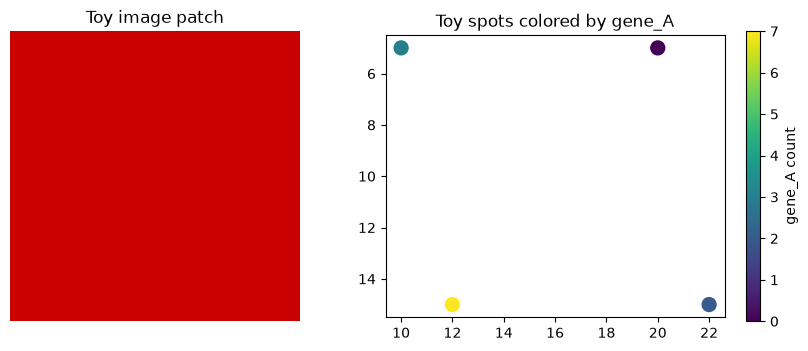

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].imshow(toy_images[0])
axes[0].set_title('Toy image patch')
axes[0].axis('off')

axes[1].scatter(spots['x'], spots['y'], c=spots['gene_A'], s=100, cmap='viridis')
axes[1].invert_yaxis()  # Image coordinates usually start at the top-left.
axes[1].set_aspect('equal')
axes[1].set_title('Toy spots colored by gene_A')
fig.colorbar(axes[1].collections[0], ax=axes[1], label='gene_A count')
plt.tight_layout()
plt.show()


## 10. Hugging Face Hub: sign in and download dataset files
Hugging Face Hub hosts datasets and models. HEST files may be gated: you need an account, must accept the dataset terms, and then sign in with a read token. (read/write is also okay.) `login()` prompts for the token; do not put a token in a saved cell or commit it. The README describes environment-variable and manual-entry alternatives.

To access the dataset for this project, create a Hugging Face account, accept the access terms for the HEST dataset and GenBio-PathFM model, and create a read token. Choose one sign-in method:

- **Environment variable:** Set a variable named `HF_TOKEN` in your local environment (see an example in `.env.example`), and that logs you in. Keep `.env` private and out of Git.
- **Interactive login:** run `from huggingface_hub import login` followed by `login()`, then enter the token in the prompt.

In [62]:
login()  # Enter your token in the prompt (when env variable is not set)
print(whoami())  # ensures that you are logged in and shows your username and token scopes.

with tempfile.TemporaryDirectory() as temporary_folder:
    metadata_dir = Path(temporary_folder)
    metadata_dir.mkdir(parents=True, exist_ok=True)
    metadata_file = hf_hub_download(
        repo_id='MahmoodLab/hest',
        repo_type='dataset',
        filename='HEST_v1_1_0.csv',
        local_dir=metadata_dir,
    )
    print('Downloaded metadata to:', metadata_file)

    # Read and display the first few rows of the metadata CSV file
    metadata = pd.read_csv(metadata_file)
    display(metadata.head())


{'type': 'user', 'id': '6ab4394a4d67ecbb19663599', 'name': 'Accord985', 'fullname': 'Siyu Wang', 'email': 'bwang120@jh.edu', 'emailVerified': True, 'canPay': False, 'billingMode': 'prepaid', 'periodEnd': 1796083200, 'isPro': False, 'avatarUrl': 'https://cdn-avatars.huggingface.co/v1/production/uploads/no-auth/pPg2Lk8db_dtGTm6Y_XM2.png', 'orgs': [], 'auth': {'type': 'access_token', 'accessToken': {'displayName': 'hest', 'role': 'read', 'createdAt': '2026-09-29T19:25:24.259Z'}}}
Downloaded metadata to: C:\Users\Siyu_\AppData\Local\Temp\tmphxqm5flm\HEST_v1_1_0.csv


,dataset_title,id,image_filename,organ,disease_state,oncotree_code,species,patient,st_technology,data_publication_date,...,treatment_comment,pixel_size_um_embedded,pixel_size_um_estimated,magnification,fullres_px_width,fullres_px_height,tissue,disease_comment,subseries,hest_version_added
0,Fresh Frozen Mouse Brain Hemisphere with 5K Mo...,TENX159,TENX159.tif,Brain,Healthy,NaN,Mus musculus,NaN,Xenium,7/31/24,...,NaN,0.273768,0.274027,40x,17051,24689,Brain,NaN,NaN,v1_1_0
1,FFPE Human Skin Primary Dermal Melanoma with 5...,TENX158,TENX158.tif,Skin,Cancer,SKCM,Homo sapiens,NaN,Xenium,7/31/24,...,NaN,0.273777,0.273754,40x,18669,35787,Skin,Primary Dermal Melanoma,NaN,v1_1_0
2,FFPE Human Prostate Adenocarcinoma with 5K Hum...,TENX157,TENX157.tif,Prostate,Cancer,PRAD,Homo sapiens,NaN,Xenium,7/31/24,...,NaN,0.273772,0.273741,40x,25002,49976,Prostate,NaN,NaN,v1_1_0
3,Characterization of immune cell populations in...,TENX156,TENX156.tif,Bowel,Cancer,COAD,Homo sapiens,Patient 1,Visium HD,7/11/24,...,NaN,0.264583,0.273802,40x,71106,58791,Colon,Stage II-A,"Visium HD, Sample P1 CRC",v1_1_0
4,Characterization of immune cell populations in...,TENX155,TENX155.tif,Bowel,Cancer,COAD,Homo sapiens,Patient 1,Visium HD,7/11/24,...,NaN,0.264583,0.273874,40x,75250,48740,Colon,NaN,"Visium HD, Sample P2 CRC",v1_1_0
